In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare
from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEARCH_SPACE = {
    "minimum_profit": [1.1, 1.5, 2.0],
    "cooldown_long": [30, 60, 90],
    "cooldown_short": [7, 14, 30],
}

In [4]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experiment": {"minimum_profit": 1.1, "cooldown_long": 30.0, "cooldown_short": 7.0},
}

In [5]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,BTC,ETH,XRP,USDT,BCH,LTC,EOS,BNB,BSV,XLM,...,MKR,ONT,DOGE,VET,BAT,OMG,SNX,ZRX,ICX,QTUM
Date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,10214.379883,268.099243,0.326706,0.998579,474.317993,80.403427,5.341575,25.440100,359.041138,0.082655,...,625.763184,1.021036,0.003026,0.008026,0.295389,1.280141,0.932967,0.320865,0.394342,2.842507
2020-02-14,10312.116211,284.217499,0.334822,1.000114,491.160645,82.990349,5.361947,26.296959,360.390015,0.085796,...,638.993713,1.071109,0.003130,0.008323,0.311020,1.370907,0.992797,0.345264,0.400229,3.015611
2020-02-15,9889.424805,264.728577,0.306236,0.999128,437.664948,76.513245,4.743118,24.149651,310.077820,0.079246,...,607.280212,0.957589,0.002920,0.007440,0.280342,1.289413,0.949770,0.317226,0.360399,2.677241
2020-02-16,9934.433594,259.894714,0.295034,0.999272,415.940643,75.152588,4.412250,23.466389,285.867523,0.075079,...,634.711975,0.909603,0.002774,0.007133,0.264260,1.190897,0.945258,0.299002,0.348740,2.511193
2020-02-17,9690.142578,266.363434,0.286572,0.998474,409.344574,73.251305,4.346360,23.551378,309.441620,0.071851,...,614.943604,0.878514,0.002712,0.006756,0.266563,1.169630,1.011205,0.291352,0.344687,2.499368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31,68233.312500,2104.708252,1.340259,0.999024,466.334564,53.917908,0.075516,617.049194,13.852106,0.167265,...,1740.242554,0.083272,0.092208,0.006763,0.096228,0.054769,0.287147,0.103136,0.034007,0.887649
2026-04-01,68078.554688,2138.737061,1.347766,0.999800,454.311554,53.805855,0.078632,610.622986,14.003111,0.169253,...,1785.234497,0.112436,0.092191,0.006885,0.099325,0.055448,0.281543,0.104537,0.035458,0.930321
2026-04-02,66888.570312,2056.852539,1.318691,0.999892,444.056213,52.260174,0.076542,583.136841,14.614312,0.163015,...,1750.205811,0.108114,0.090374,0.006740,0.094341,0.053399,0.278585,0.102121,0.035270,0.879604


# SEARCH

In [6]:
history_search = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
    )

100%|██████████| 27/27 [21:15<00:00, 47.24s/it]


In [7]:
history_search

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,minimum_profit=1.1_cooldown_long=30_cooldown_s...,ADA,1782,2137,465,508,2602,52,0.629103,11,-26,-385,52.666667,24,1
1,minimum_profit=1.1_cooldown_long=30_cooldown_s...,NEO,1831,954,792,1102,1747,34,9.130139,8,-44,-1112,98.666667,10,1
2,minimum_profit=1.1_cooldown_long=30_cooldown_s...,LTC,1831,569,1452,1332,2022,41,78.390852,6,-39,-778,99.750000,-2,1
3,minimum_profit=1.1_cooldown_long=30_cooldown_s...,USDT,1782,0,1782,1782,1782,64,1.000029,0,0,-2,11.695652,0,1
4,minimum_profit=1.1_cooldown_long=30_cooldown_s...,XMR,1782,1279,1959,946,3239,77,186.738409,10,-28,-781,71.800000,10,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26995,minimum_profit=2.0_cooldown_long=90_cooldown_s...,DASH,2227,258,1629,2138,1887,28,49.761748,10,-46,-780,23.000000,-12,100
26996,minimum_profit=2.0_cooldown_long=90_cooldown_s...,BAT,1831,0,1339,1831,1339,13,0.216876,1,-62,-1366,39.428571,-23,100
26997,minimum_profit=2.0_cooldown_long=90_cooldown_s...,BNB,1782,1583,1854,1003,3438,40,378.182219,2,-39,-517,91.500000,-6,100
26998,minimum_profit=2.0_cooldown_long=90_cooldown_s...,BTC,1831,636,2871,1522,3507,49,32912.687684,3,-48,-703,76.000000,0,100


In [13]:
search_res = history_search.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

search_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
minimum_profit=1.1_cooldown_long=30_cooldown_short=7,25.04,-42.90,-903.19,1162.02,1552.19,1921.83,2714.67,2409.00,1867.50,3267.25
minimum_profit=1.5_cooldown_long=30_cooldown_short=14,19.29,-45.26,-1026.15,1455.36,1337.22,1936.90,2793.01,2478.00,1782.00,3460.50
minimum_profit=1.1_cooldown_long=30_cooldown_short=14,15.95,-42.96,-916.70,1304.70,1477.25,1918.48,2782.41,2358.50,1845.50,3317.50
minimum_profit=1.5_cooldown_long=30_cooldown_short=7,13.01,-44.70,-931.83,1291.33,1406.82,1939.67,2698.57,2506.50,1782.00,3277.75
minimum_profit=1.5_cooldown_long=60_cooldown_short=7,12.87,-45.82,-1130.68,1503.15,1267.77,1931.74,2771.34,2508.50,1788.00,3245.25
minimum_profit=1.5_cooldown_long=90_cooldown_short=7,12.61,-47.66,-1321.87,1642.40,1185.15,1926.00,2828.00,2460.50,1807.75,3251.00
minimum_profit=2.0_cooldown_long=30_cooldown_short=30,12.17,-48.77,-1281.86,1669.87,1104.29,1936.69,2774.48,2560.50,1715.75,3576.00
minimum_profit=1.5_cooldown_long=30_cooldown_short=30,11.71,-47.05,-1133.79,1517.14,1262.10,1940.57,2779.67,2412.50,1778.75,3321.25
minimum_profit=1.5_cooldown_long=90_cooldown_short=14,11.52,-48.17,-1265.72,1629.39,1051.55,1935.04,2681.39,2334.00,1782.00,3267.50


# COMPARE

In [9]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 4/4 [03:04<00:00, 46.17s/it]


In [10]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,BuyHold,USDT,1782,0,1781,1782,1781,45,1.000090,0,0,-2,20.818182,0,1
1,BuyHold,BCH,1782,0,3835,1782,3835,52,213.843438,0,-55,-2808,94.666667,5,1
2,BuyHold,LTC,1782,0,2195,1782,2195,43,78.143393,0,-47,-1366,46.000000,-4,1
3,BuyHold,USDT,1782,0,1781,1782,1781,44,1.000101,0,0,-2,14.727273,0,1
4,BuyHold,DASH,1782,0,1230,1782,1230,11,42.851192,0,-53,-480,35.600000,-41,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experiment,VET,1871,1740,511,857,2252,42,0.022322,8,-33,-603,99.666667,64,100
3996,Experiment,MKR,2029,3090,1304,937,4394,46,1248.991755,9,-44,-1792,192.000000,-5,100
3997,Experiment,BCH,2128,3424,1420,565,4844,49,201.269732,12,-38,-825,124.000000,28,100
3998,Experiment,ICX,2128,1218,1713,1508,2932,29,0.286120,16,-29,-745,36.250000,26,100


In [14]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
Experiment,16.87,-43.38,-892.03,1216.31,1477.13,1929.43,2693.93,2426.50,1854.75,3210.75
Default,12.40,-45.78,-1105.53,1479.39,1316.76,1924.21,2796.64,2376.00,1842.00,3139.50
NoConfirm,10.43,-45.98,-1078.45,1306.10,1413.84,1937.83,2720.25,2567.50,1750.50,3498.25
BuyHold,-8.69,-61.24,-2040.23,2287.74,0.00,1782.00,2287.74,1729.50,1184.75,2881.75


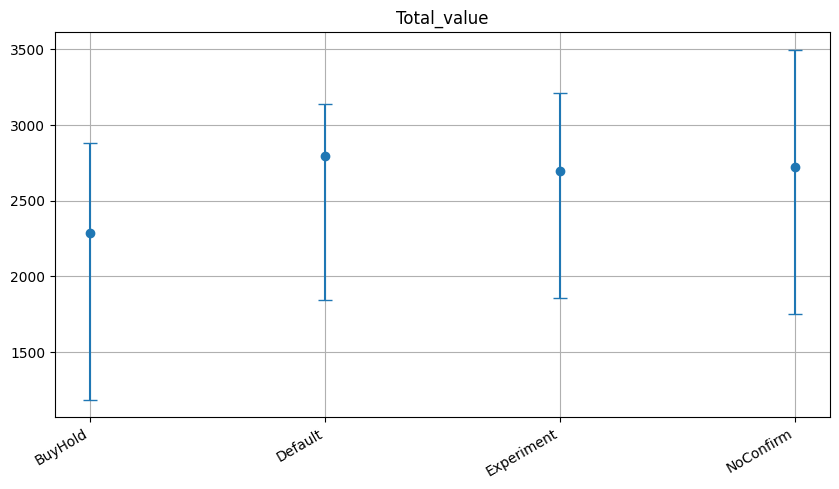

In [15]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

means = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    means.index,
    means.values,
    yerr=[means - low, high - means],
    fmt="o",
    capsize=5,
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()